# 1. Konfiguracja środowiska i import bibliotek


In [41]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import os
import torchvision.models as models
import time
from sklearn.metrics import f1_score, balanced_accuracy_score, precision_recall_fscore_support, confusion_matrix
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns

#sprawdzenie dostępności GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Używane urządzenie: {device}")

Używane urządzenie: cuda


# 2. Definicja transformacji, augmentacji i wczytanie datasetu

In [ ]:
root_directory = os.path.join("..", "data","wbcbench")

#transformacje i agumentacja danych treningowych
training_transformations = transforms.Compose([
    transforms.Resize((368, 368)),  #ujednolicenie do jednego wymiaru 368x368 pikseli
    transforms.RandomHorizontalFlip(p=0.5),  #losowe odbicie
    transforms.RandomVerticalFlip(p=0.5),    #losowe odbicia
    transforms.RandomRotation(degrees=15),   #losowa rotacja
    transforms.ColorJitter( #losowa zmiana parametrów kolorystycznych
        brightness=0.15, 
        contrast=0.15, 
        saturation=0.15, 
        hue=0.05), 
    transforms.ToTensor(), #konwersja obrazu na tensor PyTorch oraz przeskalowanie pikseli do zakresu [0.0, 1.0]
    transforms.Normalize( #normalizacja kanałów RGB zgodnie ze statystykami zbioru ImageNet
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]) 
])

#transformacja i normalizacja dla zbiorów walidacyjnego itrenignowego
evaluation_transformations = transforms.Compose([
    transforms.Resize((368, 368)), #skalowanie do 368x368
    transforms.ToTensor(), #konwersja obrazu na tensor PyTorch oraz przeskalowanie pikseli do zakresu [0.0, 1.0]
    transforms.Normalize(#normalizacja kanałów RGB zgodnie ze statystykami zbioru ImageNet
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]) 
])

#wczytanie zbioru treningowego
train_dataset = datasets.ImageFolder(
    root=os.path.join(root_directory, "train"),
    transform=training_transformations
)

#wczytanie zbioru walidacyjnego
validation_dataset = datasets.ImageFolder(
    root=os.path.join(root_directory, "val"),
    transform=evaluation_transformations
)

#wczytanie zbioru testowego
test_dataset = datasets.ImageFolder(
    root=os.path.join(root_directory, "test"),
    transform=evaluation_transformations
)

BATCH_SIZE = 32

#ładowanie danych, losowe tasowanie dla zbioru treningowego
train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(dataset=validation_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Liczba klas: {len(train_dataset.classes)}")
print(f"Etykiety klas: {train_dataset.classes}")
print(f"Liczba próbek treningowych: {len(train_dataset)}")
print(f"Liczba próbek walidacyjnych: {len(validation_dataset)}")
print(f"Liczba próbek testowych: {len(test_dataset)}")

Liczba klas: 13
Etykiety klas: ['BA', 'BL', 'BNE', 'EO', 'LY', 'MMY', 'MO', 'MY', 'PC', 'PLY', 'PMY', 'SNE', 'VLY']
Liczba próbek treningowych: 38495
Liczba próbek walidacyjnych: 8245
Liczba próbek testowych: 8262


# 3. Obliczenie wag dla klas 

In [ ]:
labels = train_dataset.targets #pobranie etykiet wszystkich próbek ze zbioru treningowego
labels_tensor = torch.tensor(labels) #konwersja listy etykiet do tensora PyTorch
class_counts = torch.bincount(labels_tensor) #zliczenie liczby wystąpień każdej klasy w zbiorze treningowym

print("Liczba zdjęć w poszczególnych klasach:")
print(class_counts)

#pobranie całkowitej liczby próbek w zbiorze treningowym oraz liczby wszystkich klas
total_samples = len(train_dataset)
num_classes = len(train_dataset.classes)

class_counts_float = class_counts.float()

#obliczenie standardowych zbalansowanych wag klas i wygładzenie pierwiastkiem
raw_weights = total_samples / (num_classes * class_counts_float)
class_weights = torch.sqrt(raw_weights)

print("Wyliczone wagi (kary) dla poszczególnych klas:")
torch.set_printoptions(sci_mode=False, precision=4)
print(class_weights)

Liczba zdjęć w poszczególnych klasach:
tensor([  599,  2497,   453,  1148, 10570,   454,  3635,   554,    71,    11,
          134, 17872,   497])
Wyliczone wagi (kary) dla poszczególnych klas:
tensor([ 2.2234,  1.0890,  2.5567,  1.6061,  0.5293,  2.5539,  0.9026,  2.3119,
         6.4580, 16.4072,  4.7009,  0.4070,  2.4409])


# 4. Transfer Learning (ResNet50)

In [62]:
#wczytanie gotowej architektury sieci ResNet50 z wstępnie wytrenowanymi wagami z ImageNet
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

#odczytanie liczby cech wejściowych, które trafiajądo oryginalnej wartstwy klasyfkacji
in_features = model.fc.in_features
#podmiana ostatniej warstwy (fc) na nową warstwę liniową, która przyjmuje 2048 cech i zwraca logits (wyniki) dla 13 klas
model.fc = nn.Linear(in_features, num_classes)

# 5. Inicjalizacja treningu

In [ ]:
model = model.to(device) #przeniesienie modelu na odpowiednie urządzenie
weights_tensor = class_weights.to(device) #przeniesienie tensora wag klas na odpowiednie urządzenie
loss_function = nn.CrossEntropyLoss(weight=weights_tensor) #definicja funkcja straty uwzględniająca wyliczone wagi 
optimizer = optim.AdamW(model.parameters(), lr=0.0001, weight_decay=1e-4) #inicjalizacja optymalizatora AdamW z mniejszym współczynnikiem uczenia oraz regularyzacją wag 

# 6. Pętla treningowa i walidacyjna

In [ ]:
EPOCHS = 50
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6) #harmonogram wygaszania współczynnika uczenia

best_macro_f1 = 0.0
patience = 12
epochs_no_improve = 0

print("======================================================================")
print("START TRENINGU (ResNet50)")
print("======================================================================")

for epoch in range(EPOCHS):
    start_time = time.time()
    
    #TRENING
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for inputs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", leave=False):
        inputs = inputs.to(device) #przeniesienie zdjęć na odpowiednie urządzenie
        labels = labels.to(device) #przeniesienie etykiet na odpowiednie urządzenie

        optimizer.zero_grad() #wyzerowanie gradientów z poprzedniego kroku
        outputs = model(inputs) #wygenerowanie predyckji
        loss = loss_function(outputs, labels) #obliczenie błędu(loss)

        loss.backward() #obliczenie gradientów dla wag modelu
        optimizer.step() #aktualizacja wagi modelu

        running_loss += loss.item() * inputs.size(0) #zsumowanie błędu z całego batcha
        _, predicted = torch.max(outputs, 1) #wybór klasy z najwyższym wynikiem

        total_samples += labels.size(0) #zwiększenie licznika wszysstkich przetworzonych klas
        correct_predictions += (predicted == labels).sum().item() #zliczenie poprawnie odgadniętych klas

    train_loss = running_loss / total_samples #obliczenie średniego błędu dla całego zbioru treningowego w tej epoce
    train_acc = (correct_predictions / total_samples) * 100 #obliczenie procentowej dokładności zbioru treningowego(accuracy)

    #WALIDACJA
    model.eval() #przełączenie modelu w tryb ewaluacji
    val_running_loss = 0.0
    val_correct = 0
    val_samples = 0
    val_true_labels = []
    val_predictions = []

    with torch.no_grad(): #wyłączenie obliczania gradientów
        for inputs, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]", leave=False):
            inputs = inputs.to(device) #przeniesienie zdjęć na odpowiednie urządzenie
            labels = labels.to(device) #przeniesienie etykiet na odpowiednie urządzenie

            outputs = model(inputs) #wygenerowanie predykcji
            loss = loss_function(outputs, labels) #obliczenię błędu(loss)

            val_running_loss += loss.item() * inputs.size(0) #zsumowanie błędu z całego batcha walidacyjnego
            _, predicted = torch.max(outputs, 1) #wybór klasy z najwyższym wynikiem

            val_samples += labels.size(0) #zwiększenie licznika wszysstkich przetworzonych klas
            val_correct += (predicted == labels).sum().item() #zliczenie poprawnie odgadniętych klas

            val_true_labels.extend(labels.cpu().tolist()) #zebranie prawdziwych etykiet
            val_predictions.extend(predicted.cpu().tolist()) #zebranie predykcji modelu

    scheduler.step() #aktualizacja współczynnika uczenia zgodnie z harmonogramem

    val_loss = val_running_loss / val_samples #obliczenie średniego błędu dla całego zbioru walidacyjnego w tej epoce
    val_acc = (val_correct / val_samples) * 100 #obliczenie procentowej dokładności zbioru walidacyjnego (accuracy)
    
    val_macro_f1 = f1_score(val_true_labels, val_predictions, average='macro') * 100 #obliczenie wskaźnika Macro F1
    val_bal_acc = balanced_accuracy_score(val_true_labels, val_predictions) * 100 #obliczenie zbalansowanej dokładności

    epoch_time = time.time() - start_time #czas trwania epoki

    print(f"Epoch {epoch+1}/{EPOCHS} [{epoch_time:.1f}s]")
    print(f"   Train - Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(f"   Val   - Loss: {val_loss:.4f} | Acc: {val_acc:.2f}%")
    print(f"   Macro F1: {val_macro_f1:.2f}% | Balanced Acc: {val_bal_acc:.2f}%")

    if val_macro_f1 > best_macro_f1:
        best_macro_f1 = val_macro_f1
        epochs_no_improve = 0
        torch.save(model.state_dict(), "best_resnet50_wbc.pth")
        print(f"   --> New best! Macro F1: {best_macro_f1:.2f}%")
    else:
        epochs_no_improve += 1
        print(f"   Epoch no improved: {epochs_no_improve}/{patience}")
        if epochs_no_improve >= patience:
            print(f"\nEarly stopping na epoce {epoch+1} (brak poprawy przez {patience} epok).")
            break

print("======================================================================")
print(f"TRENING ZAKOŃCZONY! Najlepsze Macro F1: {best_macro_f1:.2f}%")
print("======================================================================")

START TRENINGU (ResNet50)


Epoch 1/50 [620.5s]
   Train - Loss: 0.7324 | Acc: 88.57%
   Val   - Loss: 0.2914 | Acc: 92.12%
   Macro F1: 55.09% | Balanced Acc: 55.57%
   --> New best! Macro F1: 55.09%


Epoch 2/50 [603.3s]
   Train - Loss: 0.5562 | Acc: 90.91%
   Val   - Loss: 0.3152 | Acc: 90.41%
   Macro F1: 57.69% | Balanced Acc: 60.56%
   --> New best! Macro F1: 57.69%


Epoch 3/50 [595.2s]
   Train - Loss: 0.4762 | Acc: 91.75%
   Val   - Loss: 0.2693 | Acc: 91.80%
   Macro F1: 63.39% | Balanced Acc: 65.32%
   --> New best! Macro F1: 63.39%


Epoch 4/50 [595.2s]
   Train - Loss: 0.4312 | Acc: 92.33%
   Val   - Loss: 0.2919 | Acc: 91.11%
   Macro F1: 60.99% | Balanced Acc: 64.39%
   Epoch no improved: 1/12


Epoch 5/50 [603.6s]
   Train - Loss: 0.3797 | Acc: 92.94%
   Val   - Loss: 0.2360 | Acc: 92.36%
   Macro F1: 67.78% | Balanced Acc: 72.41%
   --> New best! Macro F1: 67.78%


... (38 outputs left out)

Epoch 44/50 [605.5s]
   Train - Loss: 0.0426 | Acc: 98.75%
   Val   - Loss: 0.2310 | Acc: 94.95%
   Macro F1: 77.66% | Balanced Acc: 76.16%
   Epoch no improved: 9/12


Epoch 45/50 [650.1s]
   Train - Loss: 0.0428 | Acc: 98.78%
   Val   - Loss: 0.2360 | Acc: 94.77%
   Macro F1: 77.14% | Balanced Acc: 76.29%
   Epoch no improved: 10/12


Epoch 46/50 [650.7s]
   Train - Loss: 0.0379 | Acc: 98.86%
   Val   - Loss: 0.2329 | Acc: 95.00%
   Macro F1: 77.92% | Balanced Acc: 76.25%
   Epoch no improved: 11/12


Epoch 47/50 [651.0s]
   Train - Loss: 0.0399 | Acc: 98.86%
   Val   - Loss: 0.2346 | Acc: 94.81%
   Macro F1: 77.32% | Balanced Acc: 76.10%
   Epoch no improved: 12/12

Early stopping na epoce 47 (brak poprawy przez 12 epok).
TRENING ZAKOŃCZONY! Najlepsze Macro F1: 79.58%


# 7. Wyniki walidacja 


WYNIKI WALIDACJI DLA MODELU RESNET50


Rank  Class                                 F1   Precision    Recall   Support
--------------------------------------------------------------------------------
1     PLY                             100.00%     100.00%   100.00%         2 ✅
2     BA                               98.41%     100.00%    96.88%       128 ✅
3     EO                               98.37%      98.77%    97.97%       246 ✅
4     SNE                              97.98%      98.55%    97.41%      3829 ✅
5     LY                               96.35%      96.50%    96.20%      2265 ✅
6     MO                               92.89%      95.28%    90.63%       779 ✅
7     BL                               91.93%      89.26%    94.77%       535 ✅
8     MY                               76.03%      74.19%    77.97%       118   
9     MMY                              64.04%      61.32%    67.01%        97   
10    VLY                              62.83%      59.17%    66.98%       106   
11    PC                             

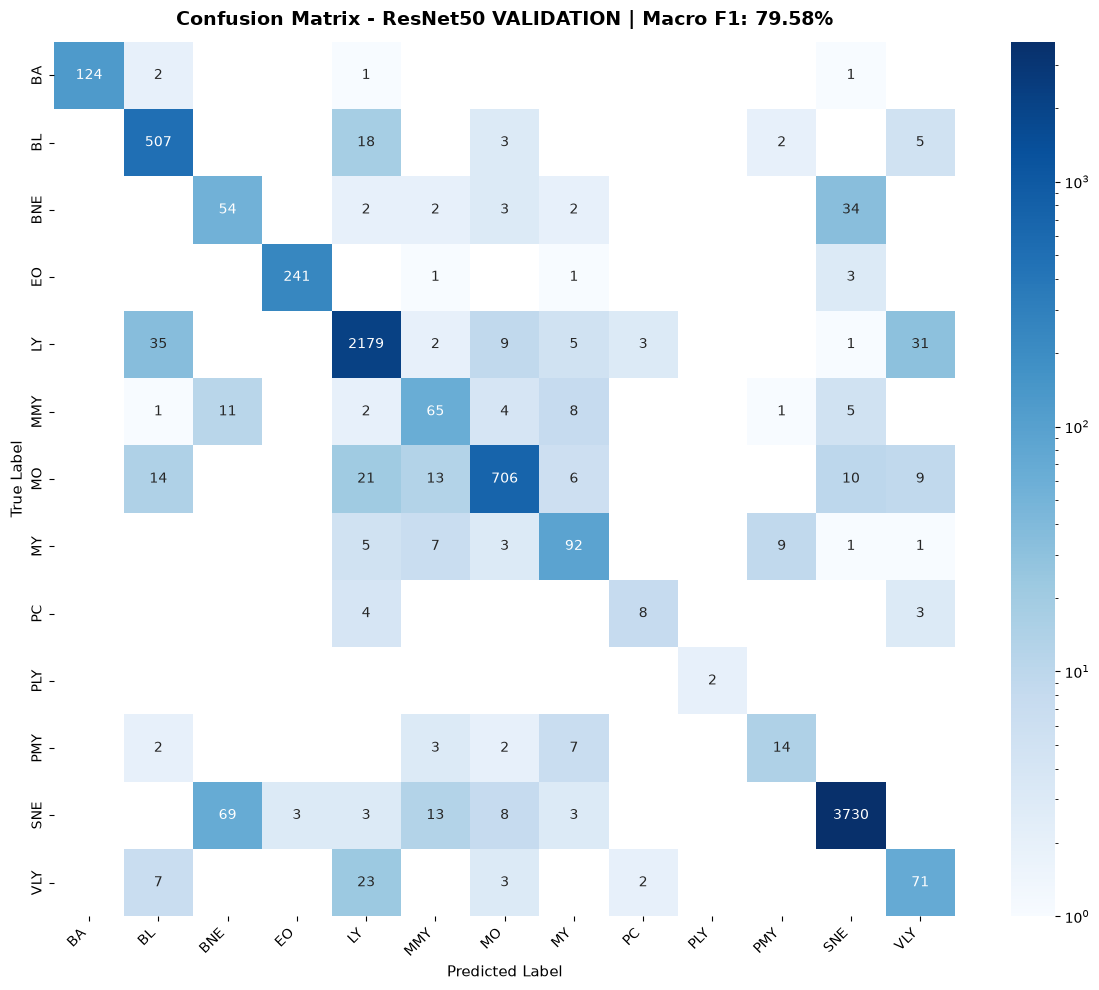

In [ ]:
class_names = train_dataset.classes
labels_index = list(range(len(class_names)))

print("\n" + "="*80)
print("WYNIKI WALIDACJI DLA MODELU RESNET50")
print("="*80)

model.load_state_dict(torch.load("best_resnet50_wbc.pth", weights_only=True))
model.eval()

all_true = []
all_predictions = []

with torch.no_grad():
    for inputs, labels in tqdm(val_loader, desc="Ewaluacja (Walidacja)", leave=False):
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        
        all_true.extend(labels.cpu().tolist())
        all_predictions.extend(predicted.cpu().tolist())

f1 = f1_score(all_true, all_predictions, labels=labels_indices, average=None, zero_division=0) * 100
prec = precision_score(all_true, all_predictions, labels=labels_indices, average=None, zero_division=0) * 100
rec = recall_score(all_true, all_predictions, labels=labels_indices, average=None, zero_division=0) * 100
supp = Counter(all_true)

stats = []
for i, name in enumerate(class_names):
    stats.append({'name': name, 'f1': f1[i], 'prec': prec[i], 'rec': rec[i], 'sup': supp.get(i, 0)})

stats = sorted(stats, key=lambda x: x['f1'], reverse=True)

print(f"{'Rank':<6}{'Class':<30}{'F1':>10}{'Precision':>12}{'Recall':>10}{'Support':>10}")
print("-"*80)
for r, s in enumerate(stats, 1):
    ind = "⚠️" if s['f1'] < 50 else ("✅" if s['f1'] >= 80 else "  ")
    print(f"{r:<6}{s['name']:<30}{s['f1']:>8.2f}%{s['prec']:>11.2f}%{s['rec']:>9.2f}%{s['sup']:>10} {ind}")

print("-"*80)
f1_vals = [s['f1'] for s in stats]
mean_f1 = np.mean(f1_vals)
print(f"{'SUMMARY':<36}{'Mean':>10}{'Std':>12}{'Min':>10}{'Max':>10}")
print(f"{'F1 Score':<36}{mean_f1:>8.2f}%{np.std(f1_vals):>11.2f}%{np.min(f1_vals):>9.2f}%{np.max(f1_vals):>9.2f}%")
print("="*80 + "\n")

cm = confusion_matrix(all_true, all_predictions, labels=labels_indices)
plt.figure(figsize=(12, 10))
ax = sns.heatmap(cm, mask=(cm == 0), annot=True, fmt='d', cmap='Blues',
                 norm=LogNorm(vmin=1, vmax=cm.max()), xticklabels=class_names, yticklabels=class_names, cbar=True)
ax.set_facecolor('white')
plt.title(f'Confusion Matrix - ResNet50 VALIDATION | Macro F1: {mean_f1:.2f}%', fontsize=14, pad=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=11)
plt.ylabel('True Label', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=90, va='center')
plt.tight_layout()
plt.savefig('confusion_matrix_resnet50_validation.png', dpi=300, bbox_inches='tight')
plt.show()

# 8. Wyniki test


WYNIKI TESTU DLA MODELU RESNET50


Rank  Class                                 F1   Precision    Recall   Support
--------------------------------------------------------------------------------
1     SNE                              98.04%      98.96%    97.13%      3831 ✅
2     EO                               97.36%      97.17%    97.56%       246 ✅
3     BA                               97.25%      99.20%    95.38%       130 ✅
4     LY                               96.50%      96.88%    96.11%      2265 ✅
5     MO                               93.18%      94.47%    91.92%       780 ✅
6     BL                               92.86%      91.19%    94.59%       536 ✅
7     MY                               76.45%      71.22%    82.50%       120   
8     PMY                              66.67%      63.64%    70.00%        30   
9     PC                               64.29%      75.00%    56.25%        16   
10    VLY                              63.07%      57.14%    70.37%       108   
11    MMY                           

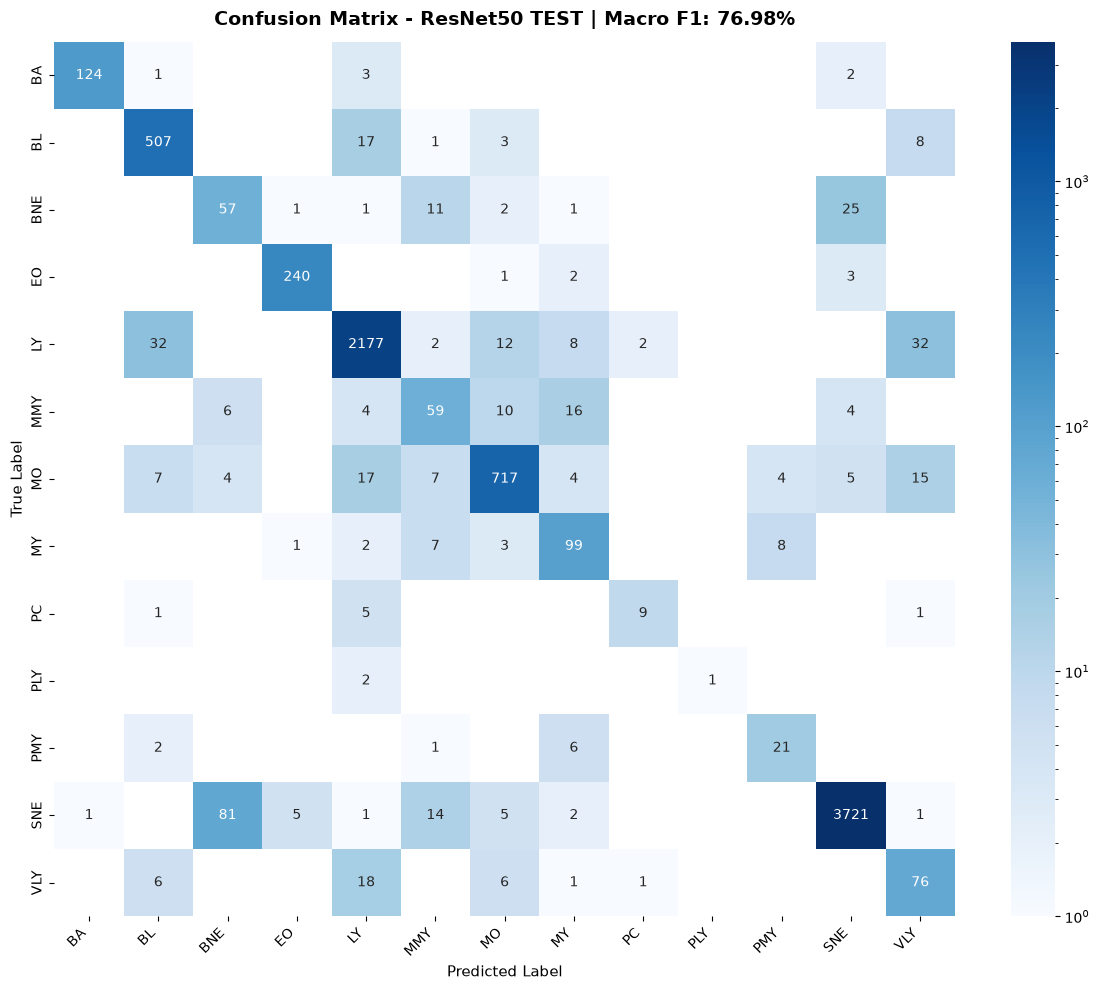

In [ ]:
class_names = train_dataset.classes
labels_index = list(range(len(class_names)))

print("\n" + "="*80)
print("WYNIKI TESTU DLA MODELU RESNET50")
print("="*80)

model.load_state_dict(torch.load("best_resnet50_wbc.pth", weights_only=True))
model.eval()

all_true = []
all_predictions = []

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Ewaluacja (Test)", leave=False):
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        
        all_true.extend(labels.cpu().tolist())
        all_predictions.extend(predicted.cpu().tolist())

f1 = f1_score(all_true, all_predictions, labels=labels_indices, average=None, zero_division=0) * 100
prec = precision_score(all_true, all_predictions, labels=labels_indices, average=None, zero_division=0) * 100
rec = recall_score(all_true, all_predictions, labels=labels_indices, average=None, zero_division=0) * 100
supp = Counter(all_true)

stats = []
for i, name in enumerate(class_names):
    stats.append({'name': name, 'f1': f1[i], 'prec': prec[i], 'rec': rec[i], 'sup': supp.get(i, 0)})

stats = sorted(stats, key=lambda x: x['f1'], reverse=True)

print(f"{'Rank':<6}{'Class':<30}{'F1':>10}{'Precision':>12}{'Recall':>10}{'Support':>10}")
print("-"*80)
for r, s in enumerate(stats, 1):
    ind = "⚠️" if s['f1'] < 50 else ("✅" if s['f1'] >= 80 else "  ")
    print(f"{r:<6}{s['name']:<30}{s['f1']:>8.2f}%{s['prec']:>11.2f}%{s['rec']:>9.2f}%{s['sup']:>10} {ind}")

print("-"*80)
f1_vals = [s['f1'] for s in stats]
mean_f1 = np.mean(f1_vals)
print(f"{'SUMMARY':<36}{'Mean':>10}{'Std':>12}{'Min':>10}{'Max':>10}")
print(f"{'F1 Score':<36}{mean_f1:>8.2f}%{np.std(f1_vals):>11.2f}%{np.min(f1_vals):>9.2f}%{np.max(f1_vals):>9.2f}%")
print("="*80 + "\n")

cm = confusion_matrix(all_true, all_predictions, labels=labels_indices)
plt.figure(figsize=(12, 10))
ax = sns.heatmap(cm, mask=(cm == 0), annot=True, fmt='d', cmap='Blues',
                 norm=LogNorm(vmin=1, vmax=cm.max()), xticklabels=class_names, yticklabels=class_names, cbar=True)
ax.set_facecolor('white')
plt.title(f'Confusion Matrix - ResNet50 TEST | Macro F1: {mean_f1:.2f}%', fontsize=14, pad=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=11)
plt.ylabel('True Label', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=90, va='center')
plt.tight_layout()
plt.savefig('confusion_matrix_resnet50_test.png', dpi=300, bbox_inches='tight')
plt.show()